# Simulate 2-D elastic waves (velocity-stress)

Virieux's velocity-stress system on a staggered grid, with the Lamé parameters computed once per run from `vp`, `vs` and `rho` (`Coefficient`). An explosive source (on `sxx` and `szz`) sends out a P wave; at the interface it converts into reflected and transmitted P and S waves, the slower S waves showing best on `vx`.

In [1]:
import numpy as np
import sympy
import torch
from IPython.display import Image

from sweep.propagator.options import EagerOptions, Full
from sweep.propagator.torch import PropTorch
from sweep.symbolic import PDE, Coefficient, Eq, Field, Model, laplace

dev = "cuda" if torch.cuda.is_available() else "cpu"
torch.backends.cudnn.allow_tf32 = False                 # full fp32 stencils
opts = EagerOptions(use_compile=False)

Helpers: a Ricker wavelet, a run that keeps snapshots, and a GIF writer.

In [2]:
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation, PillowWriter


def ricker(nt, dt, f0):
    a = (np.pi * f0 * (np.arange(nt) * dt - 1.5 / f0)) ** 2
    return torch.tensor((1 - 2 * a) * np.exp(-a), dtype=torch.float32)


def snapshots(solver, wavelet, sources, receivers, models, every=10, **kwargs):
    """Run one batch; return the record, every field every `every` steps (cropped to the model) and the times."""
    steps = list(range(every - 1, solver.nt, every))
    with torch.no_grad():
        record, snap = solver(wavelet, sources, receivers, models=models, return_wavefield=True,
                              snapshot_times=steps, **kwargs)
    nz, nx = models[0].shape[-2:]
    x0, _, z0, _ = solver._runtime_padding()
    if snap.shape[-2] - nz < z0 or snap.shape[-1] - nx < x0:   # padding not as reported: centre the crop
        z0, x0 = (snap.shape[-2] - nz) // 2, (snap.shape[-1] - nx) // 2
    snap = snap[..., z0:z0 + nz, x0:x0 + nx]
    names = [f.name for f in solver.equation.field_specs]
    frames = {n: snap[:, i, :, 0].numpy() for i, n in enumerate(names) if not n.startswith("_")}
    return record.cpu(), frames, (np.array(steps) + 1) * float(solver.dt)


def save_gif(path, panels, times, extent, xlabel="x (km)", ylabel="z (km)", unit="s", cmap="seismic",
             clip=99.8, outline=None, normalize=False):
    """Animate panels [(title, frames (nframe, nz, nx))] with fixed colour limits; outline: a model drawn as contours."""
    aspect = abs(extent[1] - extent[0]) / abs(extent[2] - extent[3])
    fig, axes = plt.subplots(1, len(panels), figsize=((3.2 * aspect + 0.45) * len(panels), 3.6),
                             squeeze=False, constrained_layout=True)
    outlines = outline if isinstance(outline, list) else [outline] * len(panels)
    images = []
    for k, (ax, (title, data), line) in enumerate(zip(axes[0], panels, outlines)):
        if normalize:
            data = data / np.abs(data).max(axis=(1, 2), keepdims=True).clip(min=1e-30)
        if cmap == "seismic":
            a = np.percentile(np.abs(data), clip) or 1.0
            lo, hi = -a, a
        else:
            lo, hi = np.percentile(data, [100 - clip, clip])
        im = ax.imshow(data[0], cmap=cmap, vmin=lo, vmax=hi, extent=extent, interpolation="bilinear")
        if line is not None:
            ax.contour(line, levels=6, colors="k", linewidths=0.5, alpha=0.35, extent=extent, origin="upper")
        ax.set(title=title, xlabel=xlabel)
        if k == 0:
            ax.set_ylabel(ylabel)
        else:
            ax.tick_params(labelleft=False)
        images.append((im, data))
    clock = fig.suptitle("")

    def draw(i):
        for im, data in images:
            im.set_data(data[i])
        clock.set_text(f"t = {times[i]:.3g} {unit}")

    FuncAnimation(fig, draw, frames=len(times)).save(path, writer=PillowWriter(fps=10), dpi=70)
    plt.close(fig)
    return path

## The PDE

Declare the models and fields, write one equation per field, and build the equation class.

In [3]:
vp, vs, rho = Model("vp", unit="m/s"), Model("vs", unit="m/s"), Model("rho", unit="kg/m^3")
lam = Coefficient("lam", rho * (vp**2 - 2 * vs**2))
mu = Coefficient("mu", rho * vs**2)

vx = Field("vx", time_order=1, stagger="x", source=True, receiver=True)
vz = Field("vz", time_order=1, stagger="z", source=True, receiver=True)
sxx = Field("sxx", time_order=1, source=True, receiver=True)
szz = Field("szz", time_order=1, source=True, receiver=True)
sxz = Field("sxz", time_order=1, stagger=("z", "x"), source=True)

pde = PDE([Eq(vz.dt, (szz.dz + sxz.dx) / rho),
           Eq(vx.dt, (sxx.dx + sxz.dz) / rho),
           Eq(szz.dt, (lam + 2 * mu) * vz.dz + lam * vx.dx),
           Eq(sxx.dt, (lam + 2 * mu) * vx.dx + lam * vz.dz),
           Eq(sxz.dt, mu * (vx.dz + vz.dx))], name="ElasticDSL")
Elastic = pde.build(ndim=2)
pde

PDE([Eq(vz.dt, (sxz.dx + szz.dz)/rho), Eq(vx.dt, (sxx.dx + sxz.dz)/rho), Eq(szz.dt, lam*vx.dx + (lam + 2*mu)*vz.dz), Eq(sxx.dt, lam*vz.dz + (lam + 2*mu)*vx.dx), Eq(sxz.dt, mu*(vx.dz + vz.dx))], name='ElasticDSL')

## Run it

A model, a propagator, one shot; a snapshot of every field is kept at regular steps.

In [4]:
nz, nx, h, dt, nt = 200, 300, 5.0, 4e-4, 1500
z = np.mgrid[0:nz, 0:nx][0]
vp_m = np.where(z > 100, 3000.0, 2000.0)
models = [torch.tensor(a, dtype=torch.float32, device=dev)
          for a in (vp_m, vp_m / 1.8, np.where(z > 100, 2300.0, 2000.0))]

solver = PropTorch(Elastic(8, device=dev), shape=(nz, nx), dh=h, dt=dt, nt=nt, dev=dev,
                   impl="eager", memory=Full(), source_type=["sxx", "szz"], receiver_type=["vz"], eager_options=opts)
src = np.array([[150, 50]])
rec = np.array([[[ix, 5] for ix in range(nx)]])
record, frames, t = snapshots(solver, ricker(nt, dt, 15.0), src, rec, models, every=30)

## The wavefield

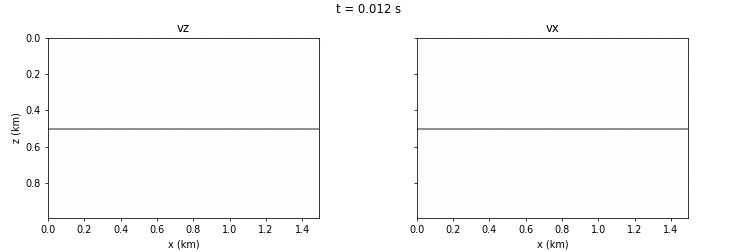

In [5]:
ext = [0, (nx - 1) * h / 1e3, (nz - 1) * h / 1e3, 0]
gif = save_gif("76_symbolic_elastic.gif", [("vz", frames["vz"][:, 0]), ("vx", frames["vx"][:, 0])], t, ext,
               outline=vp_m)
Image(filename=gif)